# U-Net–ResNet18: CNN control for the shared SUIM experiment

This is a new CNN control, separate from the original SUIM paper's U-Net
architecture and published checkpoint in 02_unet_baseline.ipynb. It uses a
convolutional ResNet-18 encoder and convolutional U-Net decoder from
Segmentation Models PyTorch 0.5.0.

Run cells in order with Python (SUIM U-Net ResNet18). MODE = 'train' starts the
configured fine-tuning run. MODE = 'checkpoint' evaluates a saved SUIM checkpoint.
An ImageNet encoder alone is not a trained SUIM model.

The encoder starts from the exact torchvision ImageNet-1k V1 weight file used
for our hybrid, verified by its full SHA-256. The training/validation split,
five foreground targets, image geometry, normalization, augmentation, batch
size, seed, optimizer, 50-epoch budget, and main validation-loss checkpoint policy
match the shared experiment. The hybrid additionally uses an auxiliary training
loss; this CNN does not. Decoder widths and topology differ, so this is a better
controlled model comparison, not an isolated experiment on attention alone.

The CNN reads the existing cleaned training copy and does not clean data.
Images and targets remain 320 x 240. The forward wrapper reflects input edges
to a multiple of 32, matching the hybrid's input geometry, then crops logits
back before BCE or scoring.

Four original TEST image files also occur in the training/validation pool.
The primary comparison uses the 106 images without those exact overlaps. The
original 110-image result is retained as a benchmark reference. Both evaluations
use the same checkpoint selected solely by validation loss.

## Environment

Reuse the existing PyTorch environment. From the project root in PowerShell:

~~~powershell
.\.venv-segformer\Scripts\python.exe -m pip install -r requirements-unet-resnet18.txt
.\.venv-segformer\Scripts\python.exe -m ipykernel install --sys-prefix --name suim-unet-resnet18 --display-name "Python (SUIM U-Net ResNet18)"
~~~

Select Python (SUIM U-Net ResNet18), or .venv-segformer/Scripts/python.exe, as the
kernel. This environment already has the matching CUDA torch/torchvision builds.
On a new machine first follow the PyTorch setup in the SegFormer notebook.
ResNet-18 weights use .cache/torch/checkpoints/; saved SUIM checkpoint evaluation
is local and does not download encoder weights.

In [1]:
import hashlib
import json
import math
import os
from pathlib import Path
from types import SimpleNamespace
import random
import time

os.environ.setdefault('HF_HUB_DISABLE_XET', '1')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import affine_transform, binary_dilation
from IPython.display import display
from tqdm.auto import tqdm
try:
    import torch
    from torch import nn
    import torch.nn.functional as F
    from torch.utils.data import Dataset, DataLoader
    import torchvision
    import segmentation_models_pytorch as smp
except ImportError as error:
    raise ImportError('Select the U-Net ResNet18 kernel and install requirements-unet-resnet18.txt.') from error

print('PyTorch:', torch.__version__, '| torchvision:', torchvision.__version__, '| SMP:', smp.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

C:\Users\darre\OneDrive\Desktop\SUIM\.venv-segformer\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.8.0+cu126 | torchvision: 0.23.0+cu126 | SMP: 0.5.0
CUDA available: True
GPU: NVIDIA GeForce RTX 3070 Laptop GPU


## Configuration

**MODE = 'train' starts the full configured fine-tuning run when its cell is run.**
Use MODE = 'checkpoint' to evaluate the saved best SUIM weights instead.
The default training data is cleaned_suim/train_val/. Run the separate cleaning
script first if that directory is missing.

The existing U-Net split is checked by image SHA-256 and reused. If its CSV is
unavailable, the identical grouped, seeded U-Net algorithm recreates the split.
An existing split with missing images, changed image bytes, or leakage is refused.

Keep MAX_TEST_IMAGES = None for all 110 TEST images. A smaller value is a partial
smoke run and is marked in reports. The notebook always overwrites this model's
own fixed output folder and replaces its previous masks, including stale masks
from larger runs. Other models' outputs are untouched.

The image normalization below matches the shared torchvision ImageNet-1k
ResNet-18 weights. Training geometry matches our U-Net notebook: initial nearest
resizing, shared affine parameters, linear image interpolation, nearest mask
interpolation, and nearest edge fill. TEST image resizing is bicubic.

In [2]:
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'train_val/images').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Set ROOT to the SUIM project containing train_val/ and TEST/.')
ROOT = ROOT.resolve()
MODE = 'train'  # 'train' fine-tunes ImageNet weights; 'checkpoint' evaluates SUIM weights.
TRAIN_DIR = ROOT / 'cleaned_suim/train_val'
TEST_DIR = ROOT / 'TEST'
SPLIT_PATH = ROOT / 'data/test/output/unet/split.csv'
OUTPUT_DIR = ROOT / 'data/test/output/unet_resnet18'
CKPT_DIR = ROOT / 'ckpt/unet_resnet18'
CUSTOM_WEIGHTS = CKPT_DIR / 'best.pt'
MODEL_ID = 'torchvision/resnet18/IMAGENET1K_V1'
MODEL_REVISION = 'f37072fd'
BACKBONE_WEIGHTS_URL = 'https://download.pytorch.org/models/resnet18-f37072fd.pth'
EXPECTED_ENCODER_SHA256 = 'f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec'
MODEL_CACHE = ROOT / '.cache/torch/checkpoints'
MODEL_CONFIG = dict(encoder_name='resnet18', encoder_depth=5,
                    decoder_channels=[256, 128, 64, 32, 16], decoder_use_norm='batchnorm',
                    decoder_interpolation='nearest', classes=5)

WIDTH, HEIGHT = 320, 240
BATCH_SIZE = 2
INFERENCE_BATCH_SIZE = 1
EPOCHS = 50
LEARNING_RATE = 6e-5
WEIGHT_DECAY = 0.01
VALIDATION_FRACTION = 0.2
SEED = 42
PREDICTION_THRESHOLD = 0.5
MAX_TEST_IMAGES = None
USE_AUGMENTATION = True
USE_AMP = True
DEVICE_NAME = 'auto'  # 'auto', 'cuda', or 'cpu'
CLASSES = ['RO', 'FV', 'HD', 'RI', 'WR']
IMAGE_MEAN = [0.485, 0.456, 0.406]
IMAGE_STD = [0.229, 0.224, 0.225]
AUGMENTATION = dict(rotation_range=0.2, width_shift_range=0.05,
                    height_shift_range=0.05, shear_range=0.05, zoom_range=0.05,
                    horizontal_flip=True, fill_mode='nearest')

if MODE not in {'train', 'checkpoint'}:
    raise ValueError('Use train or checkpoint. ImageNet weights alone cannot evaluate SUIM.')
if not (TRAIN_DIR / 'images').is_dir() or not (TRAIN_DIR / 'masks').is_dir():
    raise FileNotFoundError('Create cleaned_suim with scripts/clean_dataset.py before training/evaluation.')
if WIDTH < 32 or HEIGHT < 32 or WIDTH % 16 or HEIGHT % 16:
    raise ValueError('WIDTH and HEIGHT must be multiples of 16 and at least 32.')
if min(BATCH_SIZE, INFERENCE_BATCH_SIZE, EPOCHS) < 1:
    raise ValueError('Batch sizes and EPOCHS must be positive.')
if not 0 < VALIDATION_FRACTION < 1 or not 0 < PREDICTION_THRESHOLD < 1:
    raise ValueError('Validation fraction and prediction threshold must be between 0 and 1.')
if MAX_TEST_IMAGES is not None and (not isinstance(MAX_TEST_IMAGES, int) or MAX_TEST_IMAGES < 1):
    raise ValueError('MAX_TEST_IMAGES must be None or a positive integer.')
if DEVICE_NAME not in {'auto', 'cuda', 'cpu'}:
    raise ValueError('DEVICE_NAME must be auto, cuda, or cpu.')
if DEVICE_NAME == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('CUDA was requested but is not available in this kernel.')
DEVICE = torch.device('cuda' if DEVICE_NAME == 'auto' and torch.cuda.is_available()
                      else 'cpu' if DEVICE_NAME == 'auto' else DEVICE_NAME)
AMP_ENABLED = USE_AMP and DEVICE.type == 'cuda'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
print('Mode:', MODE, '| Device:', DEVICE, '| Mixed-precision training:', AMP_ENABLED)
print('Training:', TRAIN_DIR, '| Test:', TEST_DIR)
print('Output directory (overwritten):', OUTPUT_DIR)
print('Stride padding (bottom, right):', (-HEIGHT) % 32, (-WIDTH) % 32)

Mode: train | Device: cuda | Mixed-precision training: True
Training: C:\Users\darre\OneDrive\Desktop\SUIM\cleaned_suim\train_val | Test: C:\Users\darre\OneDrive\Desktop\SUIM\TEST
Output directory (overwritten): C:\Users\darre\OneDrive\Desktop\SUIM\data\test\output\unet_resnet18
Stride padding (bottom, right): 16 0


In [3]:
def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as file:
        for block in iter(lambda: file.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()


def index_files(folder, extensions):
    files = {}
    for path in sorted(Path(folder).iterdir()):
        if path.is_file() and path.suffix.lower() in extensions:
            if path.stem in files:
                raise ValueError(f'Ambiguous stem: {folder / path.stem}')
            files[path.stem] = path
    return files


def getRobotFishHumanReefWrecks(mask):
    colors = np.array([(1, 0, 0), (1, 1, 0), (0, 0, 1), (1, 0, 1), (0, 1, 1)])
    return np.all(np.asarray(mask)[..., None, :] == colors, axis=-1).astype(np.float32)


def processSUIMDataRFHW(image, mask):
    return np.asarray(image, dtype=np.float32) / 255.0, getRobotFishHumanReefWrecks(np.asarray(mask) > 127.5)


def grouped_split(images, validation_fraction, seed):
    groups = {}
    for stem, path in images.items():
        groups.setdefault(file_sha256(path), []).append(stem)
    if len(groups) < 2:
        raise ValueError('At least two unique image groups are needed for a split')
    hashes = np.array(sorted(groups))
    np.random.default_rng(seed).shuffle(hashes)
    n_validation = min(len(hashes) - 1, max(1, round(len(hashes) * validation_fraction)))
    validation_hashes = set(hashes[:n_validation])
    rows = [{'stem': stem, 'image_sha256': digest,
             'partition': 'validation' if digest in validation_hashes else 'train'}
            for digest, stems in sorted(groups.items()) for stem in stems]
    return pd.DataFrame(rows).sort_values('stem').reset_index(drop=True)


def load_or_create_split(images, path, validation_fraction, seed):
    if not Path(path).is_file():
        return grouped_split(images, validation_fraction, seed), 'regenerated U-Net grouped split'
    table = pd.read_csv(path, dtype={'stem': str, 'image_sha256': str, 'partition': str})
    required = ['stem', 'image_sha256', 'partition']
    if not set(required).issubset(table.columns):
        raise ValueError('Saved split must contain stem, image_sha256, and partition.')
    table = table[required].copy()
    if table.isna().any().any() or table.stem.duplicated().any() or set(table.stem) != set(images):
        raise ValueError('Saved split must contain every training image exactly once.')
    if set(table.partition) != {'train', 'validation'}:
        raise ValueError('Saved split must contain only nonempty train and validation partitions.')
    actual_hashes = {stem: file_sha256(path) for stem, path in images.items()}
    if not table.image_sha256.equals(table.stem.map(actual_hashes)):
        raise ValueError('Saved split image hashes do not match the current dataset.')
    if table.groupby('image_sha256').partition.nunique().max() != 1:
        raise ValueError('Saved split leaks duplicate images across training and validation.')
    return table.sort_values('stem').reset_index(drop=True), str(Path(path).resolve())

In [4]:
train_images = index_files(TRAIN_DIR / 'images', {'.jpg', '.jpeg', '.png'})
train_masks = index_files(TRAIN_DIR / 'masks', {'.bmp', '.png'})
if not train_images or train_images.keys() != train_masks.keys():
    raise ValueError('Cleaned training images and RGB masks must pair exactly by stem.')
split, split_source = load_or_create_split(train_images, SPLIT_PATH, VALIDATION_FRACTION, SEED)
train_stems = split.loc[split.partition == 'train', 'stem'].tolist()
validation_stems = split.loc[split.partition == 'validation', 'stem'].tolist()

test_images = index_files(TEST_DIR / 'images', {'.jpg', '.jpeg', '.png'})
if not test_images:
    raise ValueError('No TEST images found.')
ground_truth = {symbol: index_files(TEST_DIR / 'masks' / symbol, {'.bmp', '.png'}) for symbol in CLASSES}
for symbol, masks in ground_truth.items():
    if masks.keys() != test_images.keys():
        raise ValueError(f'TEST {symbol} masks must pair exactly with TEST images.')
selected_test_stems = sorted(test_images)
if MAX_TEST_IMAGES is not None:
    selected_test_stems = selected_test_stems[:MAX_TEST_IMAGES]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
split.to_csv(OUTPUT_DIR / 'split.csv', index=False, lineterminator='\n')
SPLIT_SHA256 = file_sha256(OUTPUT_DIR / 'split.csv')
print(f'{len(train_stems)} training + {len(validation_stems)} validation pairs')
print('Split source:', split_source)
print(f'{len(selected_test_stems)}/{len(test_images)} TEST images selected')

1220 training + 305 validation pairs
Split source: C:\Users\darre\OneDrive\Desktop\SUIM\data\test\output\unet\split.csv
110/110 TEST images selected


## Paired augmentation and PyTorch loader

The affine distribution and transform order match our U-Net ImageDataGenerator
settings. A private NumPy RandomState uses the same seed formula, so the affine
choice for a given training sample and epoch matches U-Net without importing
TensorFlow. Images use linear interpolation during augmentation; masks use
nearest-neighbor interpolation. Both use the same transform and horizontal flip.
There is no validation or TEST augmentation. Normalization follows ImageNet
pretraining and differs from U-Net's simple division by 255.

Mask RGB channels are thresholded at > 127.5, following the upstream SUIM policy
for noncanonical colors. Optional class-ID masks from the cleaning script are
not used. Conflicting duplicate annotations stay together in one partition.

In [5]:
def paired_augmentation(image, mask, seed):
    rng = np.random.RandomState(seed)
    height, width = image.shape[:2]
    theta = np.deg2rad(rng.uniform(-AUGMENTATION['rotation_range'], AUGMENTATION['rotation_range']))
    tx = rng.uniform(-AUGMENTATION['height_shift_range'], AUGMENTATION['height_shift_range']) * height
    ty = rng.uniform(-AUGMENTATION['width_shift_range'], AUGMENTATION['width_shift_range']) * width
    shear = np.deg2rad(rng.uniform(-AUGMENTATION['shear_range'], AUGMENTATION['shear_range']))
    zx, zy = rng.uniform(1 - AUGMENTATION['zoom_range'], 1 + AUGMENTATION['zoom_range'], 2)
    flip = rng.random_sample() < 0.5 and AUGMENTATION['horizontal_flip']
    rotation = np.array([[np.cos(theta), -np.sin(theta), 0],
                         [np.sin(theta), np.cos(theta), 0], [0, 0, 1]])
    shift = np.array([[1, 0, tx], [0, 1, ty], [0, 0, 1]])
    skew = np.array([[1, -np.sin(shear), 0], [0, np.cos(shear), 0], [0, 0, 1]])
    zoom = np.diag([zx, zy, 1])
    center = np.array([[1, 0, height / 2 - 0.5],
                       [0, 1, width / 2 - 0.5], [0, 0, 1]])
    reset = np.array([[1, 0, -height / 2 + 0.5],
                      [0, 1, -width / 2 + 0.5], [0, 0, 1]])
    matrix = center @ rotation @ shift @ skew @ zoom @ reset
    matrix = matrix[np.ix_([1, 0, 2], [1, 0, 2])]

    def apply(array, order):
        result = np.stack([affine_transform(array[..., channel], matrix[:2, :2],
                            matrix[:2, 2], order=order, mode=AUGMENTATION['fill_mode'])
                           for channel in range(array.shape[-1])], axis=-1)
        return result[:, ::-1] if flip else result

    return apply(image, 1), apply(mask, 0)


def normalize_image(image):
    image = np.asarray(image, dtype=np.float32) / 255.0
    mean = np.asarray(IMAGE_MEAN, dtype=np.float32)
    std = np.asarray(IMAGE_STD, dtype=np.float32)
    return torch.from_numpy(np.ascontiguousarray(((image - mean) / std).transpose(2, 0, 1)))


class SUIMDataset(Dataset):
    def __init__(self, stems, images, masks, size, *, augment=False):
        if not stems:
            raise ValueError('Dataset must contain at least one image.')
        self.stems, self.images, self.masks = tuple(stems), images, masks
        self.size, self.augment, self.epoch = size, augment, 0

    def __len__(self):
        return len(self.stems)

    def __getitem__(self, index):
        stem = self.stems[index]
        with Image.open(self.images[stem]) as source:
            image = source.convert('RGB')
        with Image.open(self.masks[stem]) as source:
            mask = source.convert('RGB')
        if image.size != mask.size:
            raise ValueError(f'{stem}: cleaned image and mask dimensions must match.')
        image = np.asarray(image.resize(self.size, Image.Resampling.NEAREST), dtype=np.float32)
        mask = np.asarray(mask.resize(self.size, Image.Resampling.NEAREST), dtype=np.float32)
        if self.augment:
            image, mask = paired_augmentation(image, mask, SEED + self.epoch * len(self.stems) + index)
        target = getRobotFishHumanReefWrecks(mask > 127.5)
        target = torch.from_numpy(np.ascontiguousarray(target.transpose(2, 0, 1)))
        return normalize_image(image), target


training_data = SUIMDataset(train_stems, train_images, train_masks, (WIDTH, HEIGHT),
                            augment=USE_AUGMENTATION)
validation_data = SUIMDataset(validation_stems, train_images, train_masks, (WIDTH, HEIGHT))
generator = torch.Generator().manual_seed(SEED)
training_loader = DataLoader(training_data, batch_size=BATCH_SIZE, shuffle=True, generator=generator,
                             num_workers=0, pin_memory=DEVICE.type == 'cuda')
validation_loader = DataLoader(validation_data, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=0, pin_memory=DEVICE.type == 'cuda')
print('Batches per epoch:', len(training_loader), '| Validation batches:', len(validation_loader))

Batches per epoch: 610 | Validation batches: 153


## CNN architecture, matched encoder initialization, and checkpoints

Segmentation Models PyTorch supplies a ResNet-18 CNN encoder and convolutional
U-Net decoder. Both are trainable. The model is built with encoder_weights=None,
then the exact torchvision ImageNet weight file used for the hybrid is loaded
strictly into the encoder after removing its unused classification head.
The full file SHA-256 is checked, not just the model/weight-set name.

The U-Net decoder is randomly initialized. There is no attention module or
auxiliary loss in this CNN control. A small wrapper matches the hybrid's stride
padding and crops outputs back to the actual image/target dimensions.

Checkpoint mode verifies the split, task, class order, input geometry,
normalization, encoder-weight identity, library version, and architecture.
It loads all SUIM weights locally and does not resume optimizer state or training.

In [6]:
TARGET_POLICY = 'RGB channels >127.5; five independent foreground targets; BCEWithLogitsLoss'


class UNetResNet18ForSUIM(nn.Module):
    def __init__(self, encoder_name='resnet18', encoder_depth=5,
                 decoder_channels=(256, 128, 64, 32, 16), decoder_use_norm='batchnorm',
                 decoder_interpolation='nearest', classes=5):
        super().__init__()
        self.config = dict(encoder_name=encoder_name, encoder_depth=encoder_depth,
                           decoder_channels=list(decoder_channels), decoder_use_norm=decoder_use_norm,
                           decoder_interpolation=decoder_interpolation, classes=classes)
        self.network = smp.Unet(**self.config, encoder_weights=None, in_channels=3,
                                activation=None, aux_params=None)

    def forward(self, pixel_values):
        height, width = pixel_values.shape[-2:]
        bottom, right = (-height) % 32, (-width) % 32
        if bottom or right:
            pixel_values = F.pad(pixel_values, (0, right, 0, bottom), mode='reflect')
        logits = self.network(pixel_values)
        return SimpleNamespace(logits=logits[..., :height, :width])


def checkpoint_protocol():
    return {'model': 'unet_resnet18', 'classes': CLASSES,
            'image_size_width_height': [WIDTH, HEIGHT],
            'image_mean': IMAGE_MEAN, 'image_std': IMAGE_STD, 'target_policy': TARGET_POLICY,
            'split_sha256': SPLIT_SHA256, 'model_config': MODEL_CONFIG,
            'padding_policy': 'reflect bottom/right to stride 32; crop logits before loss/scoring',
            'encoder_weights_sha256': EXPECTED_ENCODER_SHA256,
            'smp_version': smp.__version__}


def load_suim_checkpoint(path, expected_protocol):
    payload = torch.load(path, map_location='cpu', weights_only=True)
    if not isinstance(payload, dict) or not {'state_dict', 'config', 'metadata'}.issubset(payload):
        raise ValueError('Expected a SUIM U-Net ResNet18 checkpoint saved by this notebook.')
    for key, expected in expected_protocol.items():
        if payload['metadata'].get(key) != expected:
            raise ValueError(f'Checkpoint protocol mismatch: {key}')
    if payload['config'] != expected_protocol['model_config']:
        raise ValueError('Checkpoint CNN architecture differs from the configured model.')
    if payload['config']['classes'] != len(expected_protocol['classes']):
        raise ValueError('Checkpoint output channel count differs from the SUIM task.')
    restored = UNetResNet18ForSUIM(**payload['config'])
    restored.load_state_dict(payload['state_dict'], strict=True)
    return restored, payload['metadata']


def save_suim_checkpoint(model, path, metadata):
    payload = {'state_dict': {name: value.detach().cpu() for name, value in model.state_dict().items()},
               'config': dict(model.config), 'metadata': metadata}
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix('.tmp')
    torch.save(payload, temporary)
    temporary.replace(path)


def full_resolution_logits(model, images, size):
    logits = model(pixel_values=images).logits
    return F.interpolate(logits, size=size, mode='bilinear', align_corners=False)

In [7]:
BEST_WEIGHTS = CKPT_DIR / 'best.pt'
WEIGHTS_PATH = None
CHECKPOINT_METADATA = None
READY_FOR_EVALUATION = False
if MODE == 'train':
    model = UNetResNet18ForSUIM(**MODEL_CONFIG)
    state = torch.hub.load_state_dict_from_url(
        BACKBONE_WEIGHTS_URL, model_dir=str(MODEL_CACHE), map_location='cpu',
        check_hash=True, weights_only=True)
    ENCODER_WEIGHTS_SHA256 = file_sha256(MODEL_CACHE / Path(BACKBONE_WEIGHTS_URL).name)
    if ENCODER_WEIGHTS_SHA256 != EXPECTED_ENCODER_SHA256:
        raise RuntimeError('ImageNet encoder weights differ from the shared CNN/hybrid initialization.')
    encoder_state = {name: value for name, value in state.items()
                     if name not in {'fc.weight', 'fc.bias'}}
    model.network.encoder.load_state_dict(encoder_state, strict=True)
    del state, encoder_state
    print('Loaded the same ImageNet ResNet-18 weights used for the hybrid; initialized a new CNN decoder.')
else:
    if not CUSTOM_WEIGHTS.is_file():
        raise FileNotFoundError(f'No SUIM checkpoint at {CUSTOM_WEIGHTS}. Train first or set CUSTOM_WEIGHTS.')
    model, CHECKPOINT_METADATA = load_suim_checkpoint(CUSTOM_WEIGHTS, checkpoint_protocol())
    WEIGHTS_PATH = CUSTOM_WEIGHTS
    READY_FOR_EVALUATION = True
    print('Loaded SUIM checkpoint:', WEIGHTS_PATH)
model = model.to(DEVICE)
PARAMETER_COUNT = sum(parameter.numel() for parameter in model.parameters())
print('Parameters:', f'{PARAMETER_COUNT:,}')
print('Model device:', next(model.parameters()).device)

Loaded the same ImageNet ResNet-18 weights used for the hybrid; initialized a new CNN decoder.
Parameters: 14,328,789
Model device: cuda:0


## Fine-tune (only in train mode)

AdamW, learning rate 6e-5, weight decay 0.01, batch size 2, 50 epochs, and
main-head binary cross-entropy match the shared experiment. The saved split and
paired augmentation code are reused verbatim. CUDA mixed precision is used for
training; validation and final prediction use float32.

Each epoch visits the training partition once. Validation loss selects the
checkpoint, which is reloaded before TEST prediction. TEST scores never select
weights or hyperparameters. The hybrid has an extra auxiliary training objective;
this difference and the decoder architecture/size must be reported.

Weights, history, and the loss plot overwrite ckpt/unet_resnet18/. This notebook
does not replace the original paper's CNN or claim to reproduce its training
recipe.

Epoch 1/50:   0%|          | 0/610 [00:00<?, ?it/s]

Epoch 1/50:   0%|          | 1/610 [00:00<09:09,  1.11it/s]

Epoch 1/50:   0%|          | 2/610 [00:01<04:35,  2.20it/s]

Epoch 1/50:   0%|          | 3/610 [00:01<03:07,  3.24it/s]

Epoch 1/50:   1%|          | 4/610 [00:01<02:27,  4.11it/s]

Epoch 1/50:   1%|          | 5/610 [00:01<02:03,  4.88it/s]

... (30,521 outputs left out)

Epoch 50/50: 100%|█████████▉| 608/610 [01:23<00:00,  7.18it/s]

Epoch 50/50: 100%|█████████▉| 609/610 [01:23<00:00,  7.28it/s]

Epoch 50/50: 100%|██████████| 610/610 [01:23<00:00,  7.31it/s]

Epoch 50/50: loss=0.04485, val_loss=0.12474


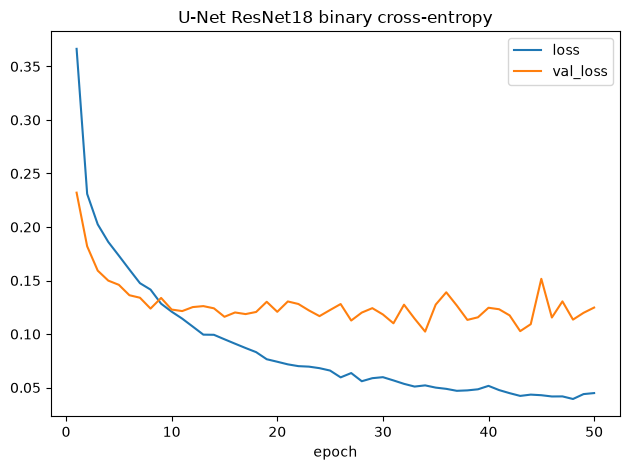

In [8]:
if MODE == 'train':
    READY_FOR_EVALUATION = False
    CKPT_DIR.mkdir(parents=True, exist_ok=True)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.BCEWithLogitsLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=AMP_ENABLED)
    history_rows = []
    best_val_loss = float('inf')
    best_written_this_run = False
    for epoch in range(EPOCHS):
        started = time.perf_counter()
        training_data.epoch = epoch
        model.train()
        train_total = 0.0
        for images, targets in tqdm(training_loader, desc=f'Epoch {epoch + 1}/{EPOCHS}', leave=False):
            images, targets = images.to(DEVICE), targets.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED):
                logits = full_resolution_logits(model, images, targets.shape[-2:])
                loss = criterion(logits, targets)
            if not torch.isfinite(loss):
                raise RuntimeError('Non-finite training loss; stop and inspect this run.')
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_total += loss.item() * images.shape[0]
        model.eval()
        validation_total = 0.0
        with torch.inference_mode():
            for images, targets in validation_loader:
                images, targets = images.to(DEVICE), targets.to(DEVICE)
                logits = full_resolution_logits(model, images, targets.shape[-2:])
                loss = criterion(logits, targets)
                if not torch.isfinite(loss):
                    raise RuntimeError('Non-finite validation loss; stop and inspect this run.')
                validation_total += loss.item() * images.shape[0]
        train_loss = train_total / len(training_data)
        val_loss = validation_total / len(validation_data)
        history_rows.append({'epoch': epoch + 1, 'loss': train_loss, 'val_loss': val_loss,
                             'seconds': time.perf_counter() - started})
        pd.DataFrame(history_rows).to_csv(CKPT_DIR / 'training_history.csv', index=False)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            metadata = {**checkpoint_protocol(), 'epoch': epoch + 1, 'val_loss': val_loss,
                        'encoder_id': MODEL_ID, 'encoder_revision': MODEL_REVISION,
                        'encoder_weights_sha256': ENCODER_WEIGHTS_SHA256,
                        'seed': SEED, 'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY,
                        'use_augmentation': USE_AUGMENTATION, 'augmentation': AUGMENTATION,
                        'mixed_precision_training': AMP_ENABLED}
            save_suim_checkpoint(model, BEST_WEIGHTS, metadata)
            best_written_this_run = True
        print(f'Epoch {epoch + 1}/{EPOCHS}: loss={train_loss:.5f}, val_loss={val_loss:.5f}')
    if not best_written_this_run:
        raise RuntimeError('This run did not produce a valid checkpoint.')
    model, CHECKPOINT_METADATA = load_suim_checkpoint(BEST_WEIGHTS, checkpoint_protocol())
    model = model.to(DEVICE)
    WEIGHTS_PATH = BEST_WEIGHTS
    READY_FOR_EVALUATION = True
    history_table = pd.DataFrame(history_rows)
    history_table.plot(x='epoch', y=['loss', 'val_loss'], title='U-Net ResNet18 binary cross-entropy')
    plt.tight_layout()
    plt.savefig(CKPT_DIR / 'training_loss.png', dpi=140)
    plt.show()
else:
    print('Training skipped; evaluating the loaded SUIM checkpoint.')

## TEST prediction and the two evaluation reports

Only a completed SUIM checkpoint is evaluated. Inputs use the shared bicubic
TEST resizing and ImageNet normalization. The padded input goes through the
CNN; logits are cropped back before sigmoid and strict > 0.5 thresholding.
Predictions overwrite data/test/output/unet_resnet18/{RO,FV,HD,RI,WR}/.

The following evaluation retains the 110-image reference score and also reports
106 images excluding the four known exact training-pool/TEST overlaps. Treat the
106-image score as the primary comparison. This audit does not establish that
all perceptually similar images or related video frames are absent.

In [9]:
def predict_and_save(model, image_paths, stems, output_dir, size, batch_size, threshold, device):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    for symbol in CLASSES:
        class_dir = output_dir / symbol
        class_dir.mkdir(exist_ok=True)
        for previous in class_dir.iterdir():
            if previous.is_file() and previous.suffix.lower() in {'.bmp', '.png'}:
                previous.unlink()
    model.eval()
    with torch.inference_mode():
        for start in range(0, len(stems), batch_size):
            selected = stems[start:start + batch_size]
            images = []
            for stem in selected:
                with Image.open(image_paths[stem]) as source:
                    image = source.convert('RGB').resize(size, Image.Resampling.BICUBIC)
                images.append(normalize_image(image))
            logits = full_resolution_logits(model, torch.stack(images).to(device), (size[1], size[0]))
            probabilities = logits.sigmoid()
            if probabilities.shape != (len(selected), len(CLASSES), size[1], size[0]):
                raise ValueError(f'Unexpected model output shape: {probabilities.shape}')
            if not torch.isfinite(probabilities).all():
                raise ValueError('Non-finite TEST predictions.')
            binary = (probabilities > threshold).cpu().numpy()
            for index, stem in enumerate(selected):
                for channel, symbol in enumerate(CLASSES):
                    Image.fromarray(binary[index, channel].astype(np.uint8) * 255).save(
                        output_dir / symbol / f'{stem}.bmp')
            if start == 0 or start + batch_size >= len(stems) or (start + batch_size) % 20 == 0:
                print(f'Predicted {min(start + batch_size, len(stems))}/{len(stems)} images')
    return output_dir

In [10]:
if not READY_FOR_EVALUATION or WEIGHTS_PATH is None:
    raise RuntimeError('Complete fine-tuning or load a SUIM checkpoint before TEST prediction.')
PREDICTION_DIR = predict_and_save(model, test_images, selected_test_stems, OUTPUT_DIR,
                                  (WIDTH, HEIGHT), INFERENCE_BATCH_SIZE, PREDICTION_THRESHOLD, DEVICE)
pd.DataFrame({'stem': selected_test_stems,
              'image_path': [str(test_images[stem]) for stem in selected_test_stems]}).to_csv(
                  OUTPUT_DIR / 'test_images.csv', index=False)

Predicted 1/110 images


Predicted 20/110 images


Predicted 40/110 images


Predicted 60/110 images


Predicted 80/110 images


Predicted 100/110 images


Predicted 110/110 images


## Boundary F-score and IoU: identical to our U-Net evaluator

The functions in the next cell are copied unchanged from 02_unet_baseline.ipynb.
This is boundary F-score, not pixel Dice/F1. Tolerance is ceil(0.008 times the image
diagonal). The evaluator resizes binary masks with bicubic interpolation and
thresholds at >= 0.5, matching the upstream evaluation policy.

Each class is scored over TEST images where that class is present in the ground
truth. False positives on absent-class images are recorded but excluded from that
class's mean, following upstream. The overall result is a macro mean of the five
class means, not global confusion-matrix IoU or eight-class mIoU. Filename
inventories must match exactly. Do not tune model settings using TEST scores.

In [11]:
def disk(radius):
    y, x = np.ogrid[-radius:radius + 1, -radius:radius + 1]
    return x * x + y * y <= radius * radius


def seg2bmap(seg):
    seg = np.asarray(seg, dtype=bool)
    if seg.ndim != 2:
        raise ValueError('Expected a two-dimensional binary mask')
    e, s, se = np.zeros_like(seg), np.zeros_like(seg), np.zeros_like(seg)
    e[:, :-1] = seg[:, 1:]
    s[:-1, :] = seg[1:, :]
    se[:-1, :-1] = seg[1:, 1:]
    boundary = seg ^ e | seg ^ s | seg ^ se
    boundary[-1, :] = seg[-1, :] ^ e[-1, :]
    boundary[:, -1] = seg[:, -1] ^ s[:, -1]
    boundary[-1, -1] = False
    return boundary


def db_eval_boundary(foreground_mask, gt_mask, bound_th=0.008):
    """
    Arguments:
        foreground_mask (ndarray): binary segmentation image.
        gt_mask         (ndarray): binary annotated image.
    Returns:
        P (float): boundaries precision
        R (float): boundaries recall
        F (float): boundaries F-measure
    """
    assert np.atleast_3d(foreground_mask).shape[2] == 1
    bound_pix = bound_th if bound_th >= 1 else \
                np.ceil(bound_th*np.linalg.norm(foreground_mask.shape))

    # Get the pixel boundaries of both masks
    fg_boundary = seg2bmap(foreground_mask);
    gt_boundary = seg2bmap(gt_mask);

    fg_dil = binary_dilation(fg_boundary,disk(int(bound_pix)))
    gt_dil = binary_dilation(gt_boundary,disk(int(bound_pix)))

    # Get the intersection
    gt_match = gt_boundary * fg_dil
    fg_match = fg_boundary * gt_dil

    # Area of the intersection
    n_fg     = np.sum(fg_boundary)
    n_gt     = np.sum(gt_boundary)

    #% Compute precision and recall
    if n_fg == 0 and  n_gt > 0:
        precision = 1
        recall = 0
    elif n_fg > 0 and n_gt == 0:
        precision = 0
        recall = 1
    elif n_fg == 0  and n_gt == 0:
        precision = 1
        recall = 1
    else:
        precision = np.sum(fg_match)/float(n_fg)
        recall    = np.sum(gt_match)/float(n_gt)

    # Compute F measure
    if precision + recall == 0:
        F = 0
    else:
        F = 2*precision*recall/(precision+recall);

    return precision, recall, F


def IoU_bin(target, prediction):
    union = np.logical_or(target, prediction).sum()
    return float(np.logical_and(target, prediction).sum() / union) if union else 1.0


def read_and_bin(path, size):
    with Image.open(path) as source:
        image = source.convert('L').resize(size, Image.Resampling.BICUBIC)
    return np.asarray(image, dtype=np.float32) / 255.0 >= 0.5


def evaluate_predictions(prediction_dir, ground_truth, stems, size):
    rows = []
    for symbol in CLASSES:
        predictions = index_files(prediction_dir / symbol, {'.bmp', '.png'})
        if set(predictions) != set(stems):
            raise ValueError(f'{symbol}: prediction stems differ from the selected TEST list')
        for stem in stems:
            real = read_and_bin(ground_truth[symbol][stem], size)
            generated = read_and_bin(predictions[stem], size)
            present = bool(real.any())
            precision, recall, f1 = db_eval_boundary(generated, real) if present else (np.nan,) * 3
            rows.append({'stem': stem, 'class': symbol, 'ground_truth_present': present,
                         'ground_truth_pixels': int(real.sum()), 'predicted_pixels': int(generated.sum()),
                         'boundary_precision': precision, 'boundary_recall': recall,
                         'boundary_f': f1, 'iou': IoU_bin(real, generated) if present else np.nan})
    per_image = pd.DataFrame(rows)
    class_rows = []
    for symbol in CLASSES:
        subset = per_image.loc[per_image['class'] == symbol]
        class_rows.append({'class': symbol, 'scored_images': int(subset.ground_truth_present.sum()),
                           'skipped_empty_gt_images': int((~subset.ground_truth_present).sum()),
                           'boundary_f_pct': 100 * subset.boundary_f.mean(), 'iou_pct': 100 * subset.iou.mean()})
    return per_image, pd.DataFrame(class_rows)

In [12]:
per_image_metrics, class_metrics = evaluate_predictions(
    PREDICTION_DIR, ground_truth, selected_test_stems, (WIDTH, HEIGHT))
per_image_metrics.to_csv(OUTPUT_DIR / 'per_image_metrics.csv', index=False)
class_metrics.to_csv(OUTPUT_DIR / 'class_metrics.csv', index=False)
display(class_metrics.round(2))

def finite_or_none(value):
    return float(value) if np.isfinite(value) else None

summary = {
    'model': 'unet_resnet18', 'mode': MODE, 'weights': str(WEIGHTS_PATH),
    'weights_sha256': file_sha256(WEIGHTS_PATH), 'checkpoint_metadata': CHECKPOINT_METADATA,
    'training_directory': str(TRAIN_DIR), 'test_directory': str(TEST_DIR),
    'train_pairs': len(train_stems), 'validation_pairs': len(validation_stems),
    'split_source': split_source, 'split_sha256': SPLIT_SHA256,
    'test_images_evaluated': len(selected_test_stems), 'test_images_available': len(test_images),
    'partial_test': len(selected_test_stems) != len(test_images),
    'classes': CLASSES, 'image_size_width_height': [WIDTH, HEIGHT], 'threshold': PREDICTION_THRESHOLD,
    'seed': SEED, 'epochs_requested': EPOCHS if MODE == 'train' else 0,
    'encoder_pretraining': 'Exact ImageNet-1k torchvision V1 encoder used by the hybrid; new CNN decoder',
    'architecture': MODEL_CONFIG, 'parameter_count': PARAMETER_COUNT, 'auxiliary_loss_weight': 0.0,
    'image_mean': IMAGE_MEAN, 'image_std': IMAGE_STD,
    'macro_boundary_f_pct': finite_or_none(class_metrics.boundary_f_pct.mean()),
    'macro_iou_pct': finite_or_none(class_metrics.iou_pct.mean()),
    'metric_protocol': 'Per-image boundary F and binary IoU; skip empty GT per class; macro mean of class means',
    'training_protocol': 'Shared grouped split and augmentation; AdamW; BCEWithLogitsLoss; best validation-loss checkpoint',
    'device': str(DEVICE), 'gpu': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else None,
    'inference_precision': 'float32', 'torch_version': str(torch.__version__),
    'smp_version': smp.__version__, 'torchvision_version': torchvision.__version__, 'numpy_version': np.__version__,
}
(OUTPUT_DIR / 'summary.json').write_text(
    json.dumps(summary, indent=2, allow_nan=False) + '\n', encoding='utf-8')
print('Macro boundary F (%):', summary['macro_boundary_f_pct'])
print('Macro IoU (%):', summary['macro_iou_pct'])
print('PARTIAL TEST RUN' if summary['partial_test'] else 'Full TEST inventory evaluated')
print('Saved predictions, split, and metrics under:', OUTPUT_DIR)

# Report the original benchmark and an additional subset without exact image-file overlap.
pool_by_hash = split.groupby('image_sha256').stem.apply(list).to_dict()
overlap_rows = []
for stem, image_path in sorted(test_images.items()):
    digest = file_sha256(image_path)
    if digest in pool_by_hash:
        overlap_rows.append({'test_stem': stem, 'train_val_stems': '|'.join(pool_by_hash[digest]),
                             'image_sha256': digest})
excluded_test_stems = {row['test_stem'] for row in overlap_rows}
filtered_metrics = per_image_metrics.loc[~per_image_metrics.stem.isin(excluded_test_stems)].copy()
filtered_rows = []
for symbol in CLASSES:
    subset = filtered_metrics.loc[filtered_metrics['class'] == symbol]
    filtered_rows.append({
        'class': symbol, 'scored_images': int(subset.boundary_f.notna().sum()),
        'skipped_empty_gt_images': int(subset.boundary_f.isna().sum()),
        'boundary_f_pct': 100 * subset.boundary_f.mean(), 'iou_pct': 100 * subset.iou.mean()})
metrics_without_exact_overlap = pd.DataFrame(filtered_rows)
filtered_metrics.to_csv(OUTPUT_DIR / 'per_image_metrics_no_exact_overlap.csv', index=False)
metrics_without_exact_overlap.to_csv(OUTPUT_DIR / 'class_metrics_no_exact_overlap.csv', index=False)
pd.DataFrame(overlap_rows, columns=['test_stem', 'train_val_stems', 'image_sha256']).to_csv(
    OUTPUT_DIR / 'exact_test_overlaps.csv', index=False)
summary['test_overlap_audit'] = {
    'scope': 'Exact SHA-256 image-file matches with the full training/validation pool only',
    'known_overlapping_test_stems': sorted(excluded_test_stems),
    'evaluated_images_after_exclusion': int(filtered_metrics.stem.nunique()),
    'macro_boundary_f_pct': finite_or_none(metrics_without_exact_overlap.boundary_f_pct.mean()),
    'macro_iou_pct': finite_or_none(metrics_without_exact_overlap.iou_pct.mean()),
    'model_weights_unchanged': True,
}
(OUTPUT_DIR / 'summary.json').write_text(
    json.dumps(summary, indent=2, allow_nan=False) + '\n', encoding='utf-8')
print('TEST images with exact matches in the training pool:', len(excluded_test_stems))
print('TEST images evaluated after excluding those matches:', filtered_metrics.stem.nunique())
print('Boundary F (%) after exclusion:', summary['test_overlap_audit']['macro_boundary_f_pct'])
print('IoU (%) after exclusion:', summary['test_overlap_audit']['macro_iou_pct'])
display(metrics_without_exact_overlap.round(2))

,class,scored_images,skipped_empty_gt_images,boundary_f_pct,iou_pct
0,RO,12,98,40.42,43.63
1,FV,66,44,63.57,58.36
2,HD,42,68,64.37,61.25
3,RI,58,52,43.96,64.13
4,WR,27,83,45.31,59.63


Macro boundary F (%): 51.526337068677876
Macro IoU (%): 57.39914446364702
Full TEST inventory evaluated
Saved predictions, split, and metrics under: C:\Users\darre\OneDrive\Desktop\SUIM\data\test\output\unet_resnet18
TEST images with exact matches in the training pool: 4
TEST images evaluated after excluding those matches: 106
Boundary F (%) after exclusion: 51.65835941225758
IoU (%) after exclusion: 57.95337527480477


,class,scored_images,skipped_empty_gt_images,boundary_f_pct,iou_pct
0,RO,10,96,44.02,48.60
1,FV,65,41,63.14,58.23
2,HD,39,67,62.57,59.78
3,RI,56,50,43.08,63.81
4,WR,26,80,45.48,59.35


## Inspect a prediction

The top row shows ground truth and the bottom row shows predictions. The metrics
above use all selected saved masks, not just this preview image. This notebook
does not benchmark inference FPS; compare speed only after defining a common
timing protocol for all models on the same hardware.

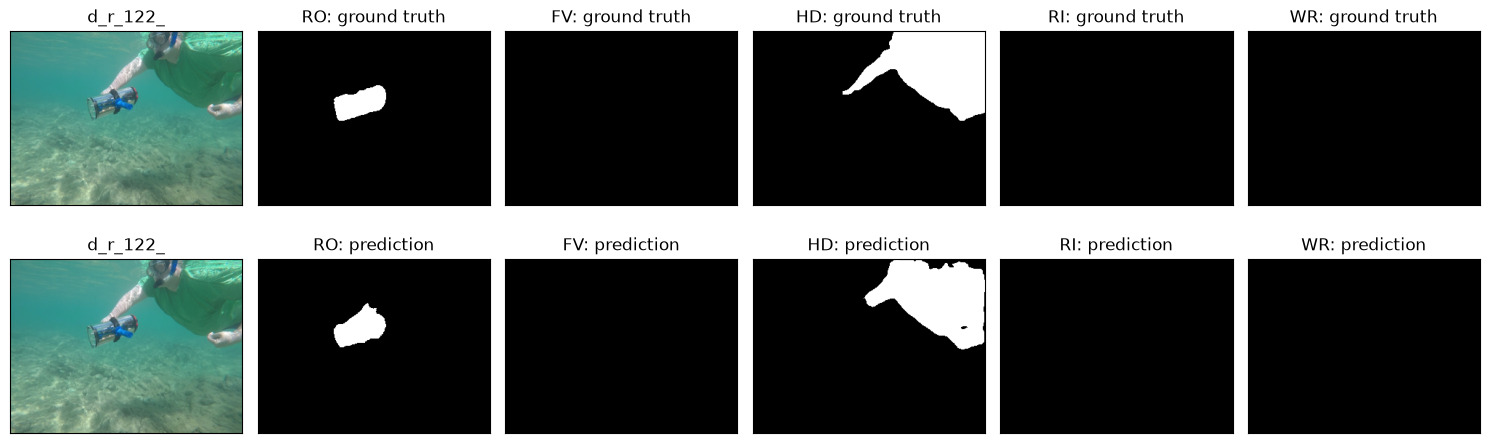

In [13]:
stem = selected_test_stems[0]
with Image.open(test_images[stem]) as source:
    image = source.convert('RGB').resize((WIDTH, HEIGHT), Image.Resampling.BICUBIC)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for row in range(2):
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(stem)
for channel, symbol in enumerate(CLASSES, start=1):
    axes[0, channel].imshow(read_and_bin(ground_truth[symbol][stem], (WIDTH, HEIGHT)), cmap='gray', vmin=0, vmax=1)
    axes[0, channel].set_title(f'{symbol}: ground truth')
    axes[1, channel].imshow(read_and_bin(PREDICTION_DIR / symbol / f'{stem}.bmp', (WIDTH, HEIGHT)), cmap='gray', vmin=0, vmax=1)
    axes[1, channel].set_title(f'{symbol}: prediction')
for axis in axes.flat:
    axis.set_xticks([])
    axis.set_yticks([])
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'prediction_example.png', dpi=140)
plt.show()

## Sources and interpretation

- [Segmentation Models PyTorch 0.5.0](https://github.com/qubvel-org/segmentation_models.pytorch/tree/v0.5.0)
- [U-Net implementation](https://github.com/qubvel-org/segmentation_models.pytorch/blob/v0.5.0/segmentation_models_pytorch/decoders/unet/model.py)
- [SMP MIT license](https://github.com/qubvel-org/segmentation_models.pytorch/blob/v0.5.0/LICENSE)
- [Torchvision ResNet-18](https://pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)
- [Original SUIM source](https://github.com/xahidbuffon/SUIM/tree/59f7cb0d4d13289434ad6e3ab162ab7a5dcc5c84)

This CNN uses the exact ImageNet encoder weight file used by our hybrid. The
common split, data conversion, augmentation, prediction, and metric functions
come from the verified PyTorch notebooks. The metric cell is identical to our
original U-Net evaluator, with a hash recorded in metadata.

The paper's original U-Net checkpoint is a separate reference, with a different
architecture and training history. Our new CNN control helps compare practical
CNN, transformer, and hybrid configurations under shared conditions. Decoder
topology/size and the hybrid's auxiliary objective still differ, so the experiment
does not isolate attention as the only causal factor.

The SUIM/DAVIS-derived data and evaluation adaptations retain the SUIM MIT notice
below. SMP is installed as a separate MIT-licensed dependency; no GeoSeg
architecture code is included in this CNN notebook.

~~~text
MIT License

Copyright (c) [2020] [Md Jahidul Islam]

SUIM-Net: Semantic Segmentation of Underwater Imagery: Dataset and Benchmark
Paper: https://arxiv.org/pdf/2004.01241.pdf
Original repository: https://github.com/xahidbuffon/SUIM-Net

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
~~~